# Figure 6

In [1]:
from riskhistory.format import rcParams
from riskhistory.config import results_pth
from riskhistory.data import (
    load_pupilacceptmodel_historyeffect_by_pupilbin,
    load_ddm_posterior,
    load_ddm_ess,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
DATASET_LABELS2 = {"equalIndifference" : "\nEqualIndifference",
                    "equalRange" : "EqualRange",
                    "sheng2020" : "\nSheng2020"}

SP_PUPIL_MODEL = "HDDM_Base_Lag1-stp_Pupil_stp"
DRIFT_PUPIL_MODEL = "HDDM_Base_Lag1-drift_Pupil_drift"

# (model_id, model name, param) -- the choice history x pupil interactions
PUPIL_INTERACTIONS = [
    (SP_PUPIL_MODEL,    "SP-CH x Pupil",    "z_choice_prev1:pupil"),
    (DRIFT_PUPIL_MODEL, "Drift-CH x Pupil", "v_choice_prev1:pupil"),
]

### Helper functions

In [2]:
def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)


def summarize_posterior(model_id, dataset, param):
    """Flatten the 4 chains into one pooled sample, then the 95% CI as the
    2.5th/97.5th percentiles."""
    samples = load_ddm_posterior(model_id, dataset)[param].flatten()
    lo, hi = np.percentile(samples, [2.5, 97.5])
    return samples, np.mean(samples), lo, hi


def plot_posterior_hists(ax, model_id, param, color, ylabel, bins=40, max_width=0.7):
    """Sideways histogram of the pooled posterior per dataset (bins on the
    y-axis), with the mean (horizontal line) and 95% interval (vertical
    line to the left of each histogram)."""
    for x, ds in enumerate(DATASETS):
        samples, mean, lo, hi = summarize_posterior(model_id, ds, param)
        counts, edges = np.histogram(samples, bins=bins)
        left = x - max_width / 2
        right_edges = left + max_width * counts / counts.max()
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  fill=True, color=color, zorder=3)
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  color="black", linewidth=1.5, zorder=3)
        ax.plot([left, left + max_width], [mean, mean], color="black",
                linewidth=2.5, zorder=4)
        ax.plot([left - 0.06, left - 0.06], [lo, hi], color="black",
                linewidth=2.5, solid_capstyle="butt", zorder=4)

    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(range(len(DATASETS)))
    ax.set_xticklabels([DATASET_LABELS2[ds] for ds in DATASETS], ha="center", fontsize = plt.rcParams["axes.labelsize"]*1.1)
    ax.set_xlim(-0.6, len(DATASETS) - 0.4)
    ax.set_ylabel(ylabel, fontsize = plt.rcParams["axes.labelsize"]*1.1)
    ax.set_ylim(-0.2, 0.2)
    ax.spines[["top", "right"]].set_visible(False)

### Figure 1: choice-history effect by pupil bin
Choice-history effect on acceptance probability (Prev. Accept − Prev. Reject) by pupil bin (median split within subject).

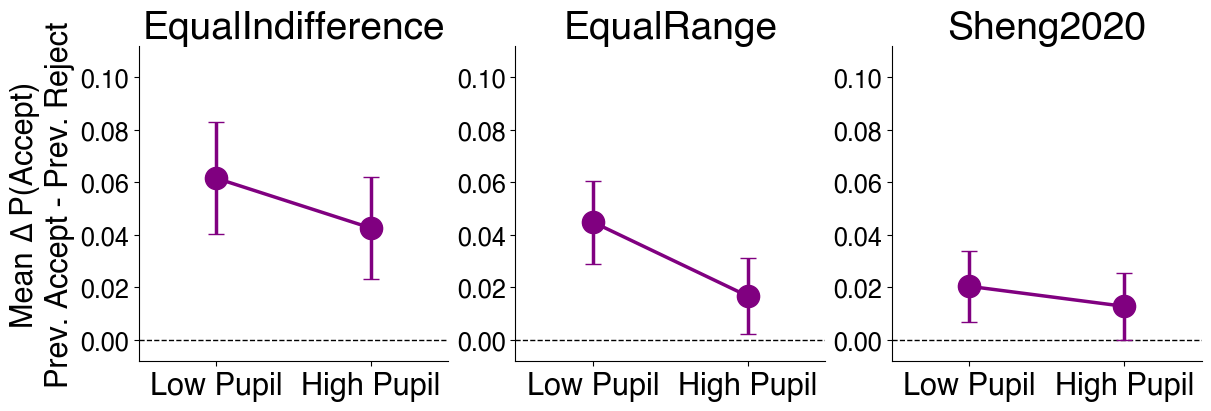

In [3]:
PUPIL_BIN_ORDER = ["Low", "High"]
PUPIL_BIN_ORDER_NAME = ["Low Pupil", "High Pupil"]
HISTORYEFFECT_COLOR = "purple"

historyeffect_by_pupilbin = load_pupilacceptmodel_historyeffect_by_pupilbin()

hist_los = historyeffect_by_pupilbin["asymp.LCL"].values
hist_his = historyeffect_by_pupilbin["asymp.UCL"].values
hist_range = hist_his.max() - hist_los.min()
HISTORYEFFECT_YLIM = (hist_los.min() - 0.1 * hist_range, hist_his.max() + 0.35 * hist_range)

fig, axes = plt.subplots(nrows=1, ncols=len(DATASETS), figsize=(12, 4), layout="constrained")

for col, ds in enumerate(DATASETS):
    ax = axes[col]
    x_pos = np.arange(len(PUPIL_BIN_ORDER))
    ds_hist = (
        historyeffect_by_pupilbin[historyeffect_by_pupilbin["dataset"] == ds]
        .set_index("pupil_bin").loc[PUPIL_BIN_ORDER]
    )

    means = ds_hist["historyeffect"].values
    los   = ds_hist["asymp.LCL"].values
    his   = ds_hist["asymp.UCL"].values

    ax.errorbar(x_pos, means, yerr=[means - los, his - means], fmt="o-", 
                color=HISTORYEFFECT_COLOR, markersize=16, capsize=6, elinewidth=2.5, linewidth=2.5, zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    ax.set_xlim(-0.5, len(PUPIL_BIN_ORDER) - 0.5)
    ax.set_ylim(*HISTORYEFFECT_YLIM)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(PUPIL_BIN_ORDER_NAME, fontsize = plt.rcParams["axes.labelsize"])
    ax.set_title(DATASET_LABELS.get(ds, ds))
    style_axis(ax, col, ylabel="Mean ∆ P(Accept)\nPrev. Accept - Prev. Reject",
               xlabel="")

fig.savefig("saved/figure5_v2_pupilbins.svg", dpi=300, bbox_inches="tight")
plt.show()

### Figure 2: SP-CH x Pupil starting-point parameter
Pooled group-level posterior per dataset from SP-CH x Pupil, as a sideways histogram (black line = mean, vertical line = 95% posterior interval) of the interaction of the choice-history shift of the starting-point bias with pupil (`z_choice_prev1:pupil`).

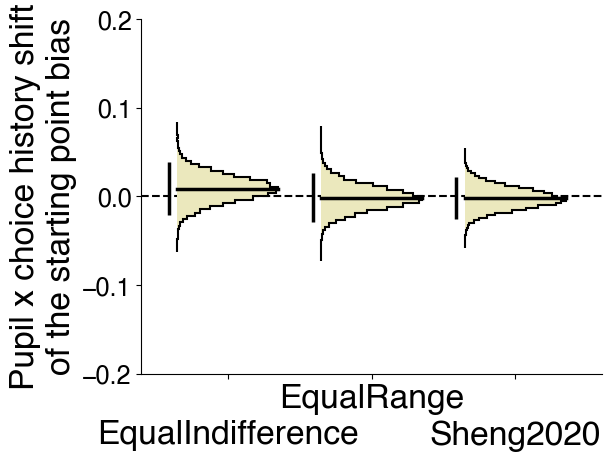

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
plot_posterior_hists(ax, SP_PUPIL_MODEL, "z_choice_prev1:pupil", "#EBE8BD",
                     "Pupil x choice history shift\nof the starting point bias")

fig.savefig("saved/figure5_v2_sp_pupil.svg", dpi=300, bbox_inches="tight")
plt.show()

### Figure 3: Drift-CH x Pupil drift parameter
Same as Figure 2 for Drift-CH x Pupil: interaction of the choice-history shift of the fixed-drift bias with pupil (`v_choice_prev1:pupil`).

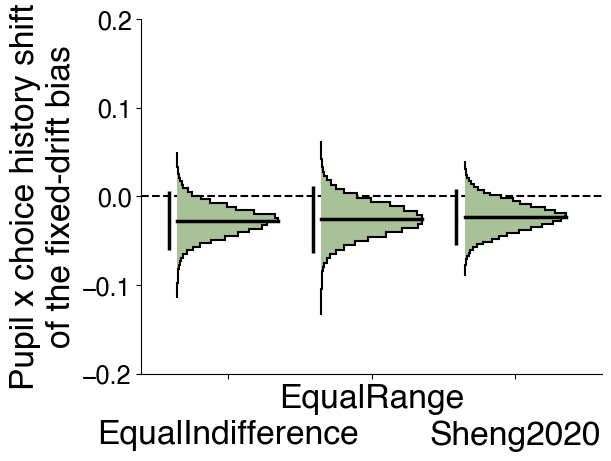

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
plot_posterior_hists(ax, DRIFT_PUPIL_MODEL, "v_choice_prev1:pupil", "#A8C199",
                     "Pupil x choice history shift\nof the fixed-drift bias")

fig.savefig("saved/figure5_v2_drift_pupil.svg", dpi=300, bbox_inches="tight")
plt.show()

### ESS: choice history x pupil interactions
Group-level effective sample size per dataset (`results/analysis_ddm/hddm_compare/{dataset}_ess.csv`).

In [6]:
ess = pd.concat([load_ddm_ess(ds) for ds in DATASETS])

ess_rows = []
for model_id, model_name, param in PUPIL_INTERACTIONS:
    for ds in DATASETS:
        match = ess[(ess["model"] == model_id) & (ess["variable"] == param) & (ess["dataset"] == ds)]
        ess_rows.append({"model": model_name, "parameter": param,
                         "dataset": DATASET_LABELS[ds], "ess": match["ess"].iloc[0]})

print(pd.DataFrame(ess_rows)
      .pivot(index=["model", "parameter"], columns="dataset", values="ess")
      [[DATASET_LABELS[ds] for ds in DATASETS]]
      .round(0).astype(int).to_string())

dataset                                EqualIndifference  EqualRange  Sheng2020
model            parameter                                                     
Drift-CH x Pupil v_choice_prev1:pupil               1103        6104       1659
SP-CH x Pupil    z_choice_prev1:pupil               1469        1733       1083


### Table: choice history x pupil posteriors
Group-level posterior mean ± half-width of the 95% posterior interval per dataset for the choice history x pupil interactions, written to `results/ddm_pupil_posterior_tables.tex`.

In [6]:
TABLE_DATASET_NAMES = {
    "equalIndifference": "EqualIndifference",
    "equalRange": "EqualRange",
    "sheng2020": "Sheng2020",
}

def escape_latex(text):
    return str(text).replace("_", "\\_")


def format_posterior_cell(samples):
    """Mean ± half-width of the 95% posterior interval."""
    lo, hi = np.percentile(samples, [2.5, 97.5])
    return f"{samples.mean():.3f} $\\pm$ {(hi - lo) / 2:.3f}"


def write_posterior_table(f, title, caption, rows):
    f.write(f"\\subsection*{{{title}}}\n\n")
    f.write("\\begin{table}[h!]\n")
    f.write("\\centering\n")
    f.write("\\begin{tabular}{ll" + "c" * len(DATASETS) + "}\n")
    f.write("\\hline\n")
    header = ["Model", "Parameter"] + [TABLE_DATASET_NAMES[ds] for ds in DATASETS]
    f.write(" & ".join(header) + " \\\\\n")
    f.write("\\hline\n")
    for model_id, model_name, param in rows:
        cells = [model_name, escape_latex(param)]
        for ds in DATASETS:
            samples, _, _, _ = summarize_posterior(model_id, ds, param)
            cells.append(format_posterior_cell(samples))
        f.write(" & ".join(cells) + " \\\\\n")
    f.write("\\hline\n")
    f.write("\\end{tabular}\n")
    f.write(f"\\caption{{{caption}}}\n")
    f.write("\\end{table}\n\n\n")
    f.write("\\newpage\n")


title = "Pupil x choice-history DDM parameters"
caption = (
    "Group-level posterior mean $\\pm$ half-width of the 95\\% posterior interval "
    "(2.5th--97.5th percentiles of the pooled samples)."
)

output_path = results_pth / "ddm_pupil_posterior_tables.tex"
with open(output_path, "w") as f:
    write_posterior_table(f, title, caption, PUPIL_INTERACTIONS)

print(output_path.read_text())

\subsection*{Pupil x choice-history DDM parameters}

\begin{table}[h!]
\centering
\begin{tabular}{llccc}
\hline
Model & Parameter & EqualIndifference & EqualRange & Sheng2020 \\
\hline
SP-CH x Pupil & z\_choice\_prev1:pupil & 0.009 $\pm$ 0.030 & -0.002 $\pm$ 0.028 & -0.002 $\pm$ 0.024 \\
Drift-CH x Pupil & v\_choice\_prev1:pupil & -0.028 $\pm$ 0.033 & -0.026 $\pm$ 0.038 & -0.023 $\pm$ 0.032 \\
\hline
\end{tabular}
\caption{Group-level posterior mean $\pm$ half-width of the 95\% posterior interval (2.5th--97.5th percentiles of the pooled samples).}
\end{table}


\newpage

